In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def read_3line(filename):
    ids = []
    seqs = []
    topos = []

    data = open(filename, "r")
    content = data.read().split("\n")
    #print(content)
    data.close()

    for i in range(len(content)):
        if content[i] == '':
            continue #gets rid of empty line at the end of the file, which would otherwise be put into ids
        if i % 3 == 0:
            ids.append(content[i])
        elif i % 3 == 1:
            seqs.append(content[i])
        else:
            topos.append(content[i])

    return ids, seqs, topos

def make_topo_result_df(id, seq, topo):
    assert len(seq) == len(topo)
    topo_dict = {"residue": list(seq),
                 "predicted_topology": list(topo)}
    df_temp = pd.DataFrame(topo_dict)
    #df_temp.to_csv(id + "_predicted_topology.csv")
    return df_temp

def plot_topology(topo_df, id = "Unnamed Protein"):
    df_outside = topo_df[topo_df["predicted_topology"] == "O"]
    df_membrane = topo_df[topo_df["predicted_topology"] == "M"]
    df_inside = topo_df[topo_df["predicted_topology"] == "I"]
    df_periplasm = topo_df[topo_df["predicted_topology"] == "P"]
    df_signal = topo_df[topo_df["predicted_topology"] == "S"]
    df_beta = topo_df[topo_df["predicted_topology"] == "B"]

    #plt.plot(test_df["predicted_topology"])
    plt.figure(figsize=(5, 1))
    plt.plot(df_signal["predicted_topology"], marker=",", ls='')
    plt.plot(df_inside["predicted_topology"], marker=",", ls='')
    plt.plot(df_membrane["predicted_topology"], marker=",", ls='')
    plt.plot(df_periplasm["predicted_topology"], marker=",", ls='')
    plt.plot(df_beta["predicted_topology"], marker=",", ls='')
    plt.plot(df_outside["predicted_topology"], marker=",", ls='')
    plt.xticks(ticks=np.arange(0, len(topos[1]), step=100), size="small")
    plt.xlabel("Sequence Position")
    plt.title("Predicted Topologies for " + id)
    plt.show()

In [3]:
ids, seqs, topos = read_3line("deeptmhmm_results/predicted_topologies.3line")

In [4]:
make_topo_result_df(ids[1], seqs[1], topos[1])


,residue,predicted_topology
0,M,I
1,S,I
2,S,I
3,R,I
4,E,I
...,...,...
1091,N,I
1092,S,I
1093,S,I
1094,S,I


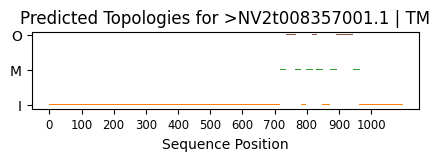

In [5]:
test_df = make_topo_result_df(ids[1], seqs[1], topos[1])
plot_topology(test_df, id=ids[1])

Text(0.5, 1.0, 'Predicted Topologies for >NV2t008357001.1 | TM')

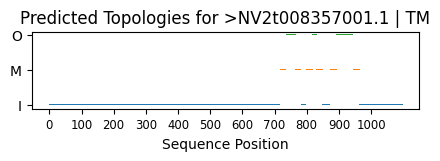

In [27]:
test_df = make_topo_result_df(ids[1], seqs[1], topos[1])
test_df_outside = test_df[test_df["predicted_topology"] == "O"]
test_df_membrane = test_df[test_df["predicted_topology"] == "M"]
test_df_inside = test_df[test_df["predicted_topology"] == "I"]

#plt.plot(test_df["predicted_topology"])
plt.figure(figsize=(5, 1))
plt.plot(test_df_inside["predicted_topology"], marker=",", ls='')
plt.plot(test_df_membrane["predicted_topology"], marker=",", ls='')
plt.plot(test_df_outside["predicted_topology"], marker=",", ls='')
plt.xticks(ticks=np.arange(0, len(topos[1]), step=100), size="small")
plt.xlabel("Sequence Position")
plt.title("Predicted Topologies for " + str(ids[1]))
